<a href="https://colab.research.google.com/github/faisu6339-glitch/RAG/blob/main/Chunking(Revision).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q langchain-nvidia-ai-endpoints chromadb faiss-cpu numpy pandas scikit-learn


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.


In [2]:

from google.colab import userdata
import os

os.environ["NVIDIA_API_KEY"] = userdata.get("NVIDIA_API_KEY")

print("NVIDIA API key configured successfully")


NVIDIA API key configured successfully


# 1. Fixed-size character chunks

In [3]:
%pip install -qU langchain langchain-core langchain-community
%pip install -qU langchain-text-splitters
%pip install -qU langchain-nvidia-ai-endpoints
%pip install -qU pypdf pandas



ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [4]:

from langchain_text_splitters import CharacterTextSplitter
from langchain_text_splitters import RecursiveCharacterTextSplitter


In [5]:

from langchain_text_splitters import CharacterTextSplitter

text = """
Python is a programming language.

Python supports object-oriented programming.

Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.

Natural language processing works with human language.
"""

splitter = CharacterTextSplitter(
    separator="\n\n",
    chunk_size=100,
    chunk_overlap=0,
    length_function=len,
    is_separator_regex=False,
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):
    print(f"Chunk {i+1}:")
    print(chunk)
    print("Length:", len(chunk))
    print("-" * 40)


Chunk 1:
Python is a programming language.

Python supports object-oriented programming.
Length: 79
----------------------------------------
Chunk 2:
Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.
Length: 93
----------------------------------------
Chunk 3:
Natural language processing works with human language.
Length: 54
----------------------------------------


# 2.Fixed-size chunks with overlap

In [6]:
text = """
Python is a programming language.

Python supports object-oriented programming.

Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.

Natural language processing works with human language.
"""

spitter=CharacterTextSplitter(
    separator="\n\n",
    chunk_size=100,
    chunk_overlap=30,
    length_function=len,
    is_separator_regex=False,
)
chunks=spitter.split_text(text)

for i , chunk in enumerate(chunks):
  print(f"chunk {i+1}:")
  print(chunk)
  print("Length:", len(chunk))

  print("-" * 40)
#

chunk 1:
Python is a programming language.

Python supports object-oriented programming.
Length: 79
----------------------------------------
chunk 2:
Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.
Length: 93
----------------------------------------
chunk 3:
Natural language processing works with human language.
Length: 54
----------------------------------------


# 3.Word-based chunks

In [7]:

from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Python is a programming language used for software development.
Machine learning helps computers learn patterns from data.
Deep learning uses neural networks to solve complex problems.
Natural language processing works with human language.
"""

# Character-based
character_splitter = RecursiveCharacterTextSplitter(
    chunk_size=50,
    chunk_overlap=0,
    length_function=len,
    separators=[" "]
)

# Word-based
word_splitter = RecursiveCharacterTextSplitter(
    chunk_size=10,
    chunk_overlap=0,
    length_function=lambda text: len(text.split()),
    separators=[" "]
)

character_chunks = character_splitter.split_text(text)
word_chunks = word_splitter.split_text(text)

print("CHARACTER-BASED CHUNKS")

for i, chunk in enumerate(character_chunks):
    print(f"Chunk {i+1}: {chunk}")
    print("Characters:", len(chunk))
    print()

print("=" * 50)

print("WORD-BASED CHUNKS")

for i, chunk in enumerate(word_chunks):
    print(f"Chunk {i+1}: {chunk}")
    print("Words:", len(chunk.split()))
    print()


CHARACTER-BASED CHUNKS
Chunk 1: Python is a programming language used for
Characters: 41

Chunk 2: software development.
Machine learning helps
Characters: 44

Chunk 3: computers learn patterns from data.
Deep learning
Characters: 49

Chunk 4: uses neural networks to solve complex
Characters: 37

Chunk 5: problems.
Natural language processing works with
Characters: 48

Chunk 6: human language.
Characters: 15

WORD-BASED CHUNKS
Chunk 1: Python is a programming language used for software development.
Machine
Words: 10

Chunk 2: learning helps computers learn patterns from data.
Deep learning uses
Words: 10

Chunk 3: neural networks to solve complex problems.
Natural language processing works
Words: 10

Chunk 4: with human language.
Words: 3



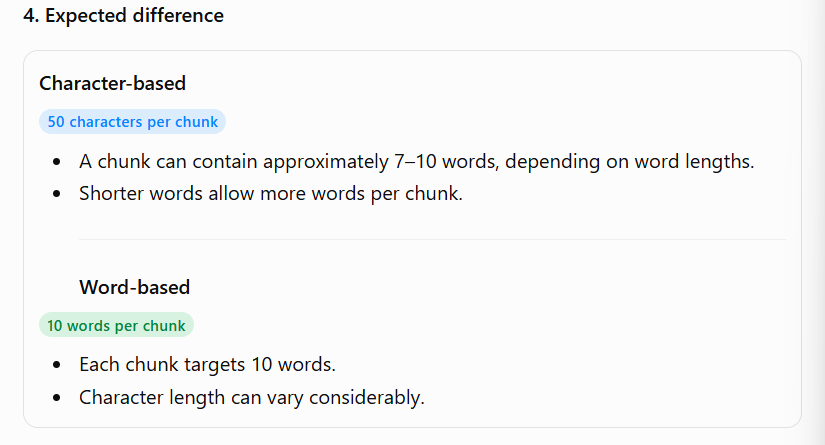

# 4.Word-based chunks with overlap

In [8]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Python is a programming language used for software development.
Machine learning helps computers learn patterns from data.
Deep learning uses neural networks to solve complex problems.
Natural language processing works with human language.
"""

word_based_splitter=RecursiveCharacterTextSplitter(
    chunk_size=80,
    chunk_overlap=3,
    separators=["\n\n", "\n", ".", "!", "?", ",", " ", ""],
    length_function=len,
)
chunks=word_based_splitter.split_text(text)

for i, chunk in enumerate(chunks):
    print(f"Chunk {i+1}: {chunk}")
    print("Words:", len(chunk.split()))
    print()

Chunk 1: Python is a programming language used for software development.
Words: 9

Chunk 2: Machine learning helps computers learn patterns from data.
Words: 8

Chunk 3: Deep learning uses neural networks to solve complex problems.
Words: 9

Chunk 4: Natural language processing works with human language.
Words: 7



# 5.Sentence splitting

In [9]:

text = """
Python is a programming language.
Python supports object-oriented programming.
Machine learning is a subset of artificial intelligence.
Deep learning uses neural networks.
Natural language processing works with human language.
"""

sentences = text.strip().split(".")

for i, sentence in enumerate(sentences):
    sentence = sentence.strip()

    if sentence:
        print(f"Sentence {i+1}:")
        print(sentence)
        print("-" * 40)


Sentence 1:
Python is a programming language
----------------------------------------
Sentence 2:
Python supports object-oriented programming
----------------------------------------
Sentence 3:
Machine learning is a subset of artificial intelligence
----------------------------------------
Sentence 4:
Deep learning uses neural networks
----------------------------------------
Sentence 5:
Natural language processing works with human language
----------------------------------------


In [10]:

from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Python is a programming language.
Python supports object-oriented programming.
Machine learning is a subset of artificial intelligence.
Deep learning uses neural networks.
Natural language processing works with human language.
"""

splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=0,
    separators=["\n", ". ", " ", ""]
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):
    print(f"Chunk {i+1}:")
    print(chunk)
    print("Length:", len(chunk))
    print("-" * 40)


Chunk 1:
Python is a programming language.
Python supports object-oriented programming.
Length: 78
----------------------------------------
Chunk 2:
Machine learning is a subset of artificial intelligence.
Deep learning uses neural networks.
Length: 92
----------------------------------------
Chunk 3:
Natural language processing works with human language.
Length: 54
----------------------------------------


# 6. N sentences per chunk

In [11]:

import nltk
from nltk.tokenize import sent_tokenize

nltk.download("punkt_tab")

text = """
Python is a programming language.
Python supports object-oriented programming.
Machine learning is a subset of artificial intelligence.
Deep learning uses neural networks.
Natural language processing works with human language.
"""

# Step 1: Split text into sentences
sentences = sent_tokenize(text)

# Step 2: Define number of sentences per chunk
n = 2

# Step 3: Create chunks
chunks = []

for i in range(0, len(sentences), n):
    chunk = " ".join(sentences[i:i+n])
    chunks.append(chunk)

# Step 4: Display chunks
for i, chunk in enumerate(chunks):
    print(f"Chunk {i+1}:")
    print(chunk)
    print("Sentence Count:", len(sent_tokenize(chunk)))
    print("-" * 50)


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Chunk 1:

Python is a programming language. Python supports object-oriented programming.
Sentence Count: 2
--------------------------------------------------
Chunk 2:
Machine learning is a subset of artificial intelligence. Deep learning uses neural networks.
Sentence Count: 2
--------------------------------------------------
Chunk 3:
Natural language processing works with human language.
Sentence Count: 1
--------------------------------------------------


# 7. Paragraph chunking

In [12]:
text = """
Python is a programming language.
Python supports object-oriented programming.

Machine learning is a subset of artificial intelligence.
It allows computers to learn from data.

Deep learning uses neural networks.
It is widely used in image recognition and NLP.

Natural language processing works with human language.
It is used in chatbots and language translation.
"""

paragraphs= text.strip().split("\n\n")

for i, paragraph in enumerate(paragraphs):
    print(f"Paragraph {i+1}:")
    print(paragraph)
    print("Character Count:", len(paragraph))
    print("Word Count:", len(paragraph.split()))
    print("-" * 50)


Paragraph 1:
Python is a programming language.
Python supports object-oriented programming.
Character Count: 78
Word Count: 9
--------------------------------------------------
Paragraph 2:
Machine learning is a subset of artificial intelligence.
It allows computers to learn from data.
Character Count: 96
Word Count: 15
--------------------------------------------------
Paragraph 3:
Deep learning uses neural networks.
It is widely used in image recognition and NLP.
Character Count: 83
Word Count: 14
--------------------------------------------------
Paragraph 4:
Natural language processing works with human language.
It is used in chatbots and language translation.
Character Count: 103
Word Count: 15
--------------------------------------------------


# What happens here?
- strip() removes unnecessary whitespace from the beginning and end.
- split("\n\n") separates paragraphs using blank lines.
- enumerate() provides paragraph numbering.
- len(paragraph) counts characters.
- len(paragraph.split()) counts words.

# 8. Paragraph-based chunking using LangChain

In [13]:

from langchain_text_splitters import CharacterTextSplitter

text = """
Python is a programming language.
Python supports object-oriented programming.

Machine learning is a subset of artificial intelligence.
It allows computers to learn from data.

Deep learning uses neural networks.
It is widely used in image recognition and NLP.

Natural language processing works with human language.
It is used in chatbots and language translation.
"""
splitter=CharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=0,
    separator="\n\n",
    length_function=len,
    is_separator_regex=False
)
chunks=splitter.split_text(text)

for i, chunk in enumerate(chunks):
    print(f"Chunk {i+1}:")
    print(chunk)
    print("Character Count:", len(chunk))
    print("Word Count:", len(chunk.split()))
    print("-" * 50)

Chunk 1:
Python is a programming language.
Python supports object-oriented programming.
Character Count: 78
Word Count: 9
--------------------------------------------------
Chunk 2:
Machine learning is a subset of artificial intelligence.
It allows computers to learn from data.
Character Count: 96
Word Count: 15
--------------------------------------------------
Chunk 3:
Deep learning uses neural networks.
It is widely used in image recognition and NLP.
Character Count: 83
Word Count: 14
--------------------------------------------------
Chunk 4:
Natural language processing works with human language.
It is used in chatbots and language translation.
Character Count: 103
Word Count: 15
--------------------------------------------------


# 9.Line-based chunking

In [14]:

text = """
Python is a programming language.
Python supports object-oriented programming.
Machine learning is a subset of artificial intelligence.
Deep learning uses neural networks.
Natural language processing works with human language.
"""

# Split text into individual lines
lines = text.strip().split("\n")

for i, line in enumerate(lines):
    print(f"Line {i+1}:")
    print(line)
    print("Character Count:", len(line))
    print("-" * 40)


Line 1:
Python is a programming language.
Character Count: 33
----------------------------------------
Line 2:
Python supports object-oriented programming.
Character Count: 44
----------------------------------------
Line 3:
Machine learning is a subset of artificial intelligence.
Character Count: 56
----------------------------------------
Line 4:
Deep learning uses neural networks.
Character Count: 35
----------------------------------------
Line 5:
Natural language processing works with human language.
Character Count: 54
----------------------------------------
